# Deserción y matrícula en educación superior en Colombia
## Objetivo y alcance
Explorar `data/gold/gold_final.csv`, sus indicadores, calidad y limitaciones.

- Deserción: Excel `articles-415244_recurso_19.xlsx`, hoja `TD - departamento`, años 2010–2024.
- Matrícula activa: API departamental `4hrb-y62g`; cobertura observada 2005–2021, aunque la descripción anuncia hasta 2024.
- La fuente municipal anterior no forma parte del flujo activo.
- El cruce por código, nivel y año es técnico; no certifica equivalencia metodológica de las poblaciones.
- No se calculan desertores multiplicando matrícula por tasa ni permanencia restando deserción a 100.
- TyT se conserva separado y sin matrícula equivalente definida.
- Los promedios departamentales simples no son tasas nacionales ponderadas.
- Según la hoja fuente, desde 2019 se excluye al SENA de deserción tecnológica; no se supone el mismo ajuste en matrícula.

El notebook solo lee archivos locales. No ejecuta el pipeline ni modifica los datos. La carga a PostgreSQL la realiza el DAG de Airflow, no este notebook.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
actual = Path.cwd().resolve()
RAIZ = next((p for p in [actual, *actual.parents] if (p / "data/gold/gold_final.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No se encontró data/gold/gold_final.csv dentro del proyecto.")
df = pd.read_csv(RAIZ / "data/gold/gold_final.csv", dtype="string", keep_default_na=False, encoding="utf-8-sig")
requeridas = {"codigo_departamento", "departamento", "nivel_formacion", "anio", "indicador", "tasa_desercion", "tasa_desercion_porcentaje", "estado_dato", "matricula_reportada", "estado_matricula", "estado_integracion_matricula", "coincidio_matricula", "par_sin_alertas_tecnicas", "requiere_revision_matricula", "variacion_calculable", "variacion_desercion_pp", "es_top20_departamental"}
if df.empty or requeridas - set(df.columns):
    raise ValueError(f"Gold vacío o incompleto. Faltan: {sorted(requeridas - set(df.columns))}")
for c in ["anio", "tasa_desercion", "tasa_desercion_porcentaje", "matricula_reportada", "variacion_desercion_pp", "anio_anterior_comparable", "tasa_anterior_comparable", "posicion_tasa", "departamentos_con_tasa_grupo", "cantidad_top20_grupo"]:
    if c in df:
        df[c] = pd.to_numeric(df[c].replace("", pd.NA), errors="raise")
df["anio"] = df["anio"].astype("Int64")
for c in ["coincidio_matricula", "par_sin_alertas_tecnicas", "requiere_revision_matricula", "variacion_calculable", "es_top20_departamental", "tasa_disponible", "alerta_revision_silver_origen"]:
    if c in df:
        texto = df[c].str.lower().str.strip()
        if (~texto.isin(["true", "false", ""])).any():
            raise ValueError(f"Bandera no reconocida: {c}")
        df[c] = texto.map({"true":True, "false":False}).astype("boolean")
print(f"Proyecto: {RAIZ.name} | Filas: {len(df):,} | Columnas: {len(df.columns)}")
display(df.head(10))


Proyecto: etl_desercion | Filas: 1,950 | Columnas: 31


,departamento,departamento_clave,nivel_formacion,anio,tasa_desercion,estado_dato,tasa_original,fuente_archivo,linea_origen,indicador,departamento_canonico,codigo_departamento,departamento_matricula,matricula_reportada,estado_matricula,alerta_revision_silver_origen,fuente_recurso,coincidio_matricula,estado_integracion_matricula,requiere_revision_matricula,tasa_desercion_porcentaje,tasa_disponible,par_sin_alertas_tecnicas,anio_anterior_comparable,tasa_anterior_comparable,variacion_desercion_pp,variacion_calculable,posicion_tasa,departamentos_con_tasa_grupo,cantidad_top20_grupo,es_top20_departamental
0,Antioquia,ANTIOQUIA,Tecnológico,2010,0.192298,reportado,0.19229822834645668,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,94171.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,19.229823,True,True,<NA>,<NA>,<NA>,False,20,30,6,False
1,Antioquia,ANTIOQUIA,Tecnológico,2011,0.153878,reportado,0.15387788778877887,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,107739.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,15.387789,True,True,2010,0.192298,-3.842034,True,18,32,7,False
2,Antioquia,ANTIOQUIA,Tecnológico,2012,0.096722,reportado,0.09672189822515107,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,102893.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,9.67219,True,True,2011,0.153878,-5.715599,True,9,33,7,False
3,Antioquia,ANTIOQUIA,Tecnológico,2013,0.092141,reportado,0.09214096391210928,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,111224.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,9.214096,True,True,2012,0.096722,-0.458093,True,10,33,7,False
4,Antioquia,ANTIOQUIA,Tecnológico,2014,0.13594,reportado,0.1359401328179205,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,110533.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,13.594013,True,True,2013,0.092141,4.379917,True,17,33,7,False
5,Antioquia,ANTIOQUIA,Tecnológico,2015,0.115184,reportado,0.11518403836751799,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,110782.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,11.518404,True,True,2014,0.13594,-2.075609,True,24,33,7,False
6,Antioquia,ANTIOQUIA,Tecnológico,2016,0.156594,reportado,0.15659440604335637,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,110904.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,15.659441,True,True,2015,0.115184,4.141037,True,7,33,7,True
7,Antioquia,ANTIOQUIA,Tecnológico,2017,0.112923,reportado,0.11292280809249866,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,113575.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,11.292281,True,True,2016,0.156594,-4.36716,True,12,33,7,False
8,Antioquia,ANTIOQUIA,Tecnológico,2018,0.098185,reportado,0.09818499400969645,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,110290.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,9.818499,True,True,2017,0.112923,-1.473781,True,18,33,7,False
9,Antioquia,ANTIOQUIA,Tecnológico,2019,0.131239,reportado,0.13123860288960584,td_departamento.csv,125,tasa_desercion_anual,ANTIOQUIA,05,ANTIOQUIA,102439.0,reportado,False,4hrb-y62g,True,COINCIDENCIA_TECNICA,False,13.12386,True,True,2018,0.098185,3.305361,True,18,31,7,False


## Diccionario de datos
Unidad de observación: departamento × nivel de formación × año.

| Columna o grupo | Significado |
|---|---|
| codigo_departamento | Código territorial textual con ceros a la izquierda. |
| departamento, departamento_clave, departamento_canonico | Nombre fuente, clave y nombre canónico para el cruce. |
| nivel_formacion, anio, indicador | Nivel, año y tasa de deserción anual. |
| tasa_desercion | Proporción; 0.10 equivale a 10 %. |
| tasa_desercion_porcentaje | Proporción multiplicada por 100. |
| estado_dato, tasa_disponible | Reportado, no_aplica o sin_dato; disponibilidad de la tasa. |
| departamento_matricula, matricula_reportada, estado_matricula | Nombre y cifra de la fuente de matrícula, con su estado. |
| coincidio_matricula, estado_integracion_matricula | Coincidencia de clave y resultado del cruce. |
| alerta_revision_silver_origen | Alerta conservada; puede incluir variantes nominales resueltas después. |
| requiere_revision_matricula | Cifra del cruce pendiente de revisión. |
| par_sin_alertas_tecnicas | Par con tasa y matrícula sin alertas técnicas definidas; no certifica comparabilidad. |
| anio_anterior_comparable, tasa_anterior_comparable | Año previo consecutivo y tasa, si ambas están disponibles. |
| variacion_desercion_pp, variacion_calculable | Cambio en puntos porcentuales y bandera de disponibilidad. |
| posicion_tasa, departamentos_con_tasa_grupo | Posición y tamaño del ranking dentro de cada año y nivel. |
| cantidad_top20_grupo, es_top20_departamental | Selección de ceil(20 % de departamentos con tasa) por año y nivel. |
| tasa_original, fuente_archivo, linea_origen | Valor textual y trazabilidad hasta la exportación de la hoja Excel. |
| fuente_recurso | Recurso de matrícula. |

`linea_origen` corresponde a la fila de la hoja del Excel. `fuente_archivo = td_departamento.csv` identifica la exportación en bronze; el manifiesto identifica el Excel original. Las 49 observaciones sin tasa se clasificaron como `no_aplica` al conservar los textos NA del Excel.


In [2]:
perfil = pd.DataFrame({"columna":df.columns, "tipo":[str(df[c].dtype) for c in df], "nulos":[int(df[c].isna().sum()) for c in df], "cadenas_vacias":[int(df[c].astype("string").eq("").sum()) for c in df], "valores_distintos":[int(df[c].nunique()) for c in df]})
display(perfil)


,columna,tipo,nulos,cadenas_vacias,valores_distintos
0,departamento,string,0,0,33
1,departamento_clave,string,0,0,33
2,nivel_formacion,string,0,0,4
3,anio,Int64,0,0,15
4,tasa_desercion,Float64,49,0,1727
5,estado_dato,string,0,0,2
6,tasa_original,string,0,0,1728
7,fuente_archivo,string,0,0,1
8,linea_origen,string,0,0,130
9,indicador,string,0,0,1


## Trazabilidad y reportes de calidad
Se leen los reportes de la ejecución activa. Las alertas pueden superponerse; no deben sumarse como grupos independientes. Las variantes de nombres detectadas en silver se resolvieron mediante el catálogo por código cuando correspondía.


In [3]:
rutas = {"Trazabilidad Excel":"data/bronze/trazabilidad_excel.json", "Silver deserción":"data/silver/calidad_desercion_departamento.json", "Silver matrícula departamental":"data/silver/calidad_matricula_departamental.json", "Integración":"data/silver/calidad_integracion.json", "Gold":"data/gold/calidad_gold.json"}
reportes = {}
for titulo, relativa in rutas.items():
    ruta = RAIZ / relativa
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {relativa}. Ejecuta main.py.")
    reporte = json.loads(ruta.read_text(encoding="utf-8"))
    reportes[titulo] = reporte
    display(Markdown(f"### {titulo}"))
    display(pd.DataFrame([{"indicador":k, "valor":v} for k,v in reporte.items() if not isinstance(v,(dict,list))]))
    for k,v in reporte.items():
        if isinstance(v,(dict,list)):
            print(k + ":")
            print(json.dumps(v, ensure_ascii=False, indent=2))


### Trazabilidad Excel

,indicador,valor
0,archivo_original,articles-415244_recurso_19.xlsx
1,ubicacion_original,data/raw/articles-415244_recurso_19.xlsx
2,sha256_excel,22eb9a08b781a8bfc39e261b0d1ea97553150cf5ce94c5...
3,hoja,TD - departamento
4,hoja_extraida,data/bronze/excel_extraido/td_departamento.csv
5,archivo_bronze,bronze_desercion_departamento.csv
6,filas_extraidas,130
7,significado_linea_origen,Número de fila de la hoja Excel. La exportació...
8,archivo_original_sin_modificar,True


filas_por_nivel:
{
  "Tecnológico": 33,
  "TyT": 33,
  "Técnico Profesional": 31,
  "Universitario": 33
}


### Silver deserción

,indicador,valor
0,archivo_fuente,td_departamento.csv
1,filas_bronze,130
2,filas_silver,1950
3,anio_minimo,2010
4,anio_maximo,2024
5,tasas_reportadas,1901
6,no_aplica,49
7,sin_dato,0
8,claves_duplicadas,0
9,tasas_fuera_rango,0


departamentos_por_nivel:
{
  "Universitario": [
    "Amazonas",
    "Antioquia",
    "Arauca",
    "Archipiélago De San Andrés, Providencia Y Santa Catalina",
    "Atlántico",
    "Bogotá D.C.",
    "Bolívar",
    "Boyacá",
    "Caldas",
    "Caquetá",
    "Casanare",
    "Cauca",
    "Cesar",
    "Chocó",
    "Cundinamarca",
    "Córdoba",
    "Guainía",
    "Guaviare",
    "Huila",
    "La Guajira",
    "Magdalena",
    "Meta",
    "Nariño",
    "Norte De Santander",
    "Putumayo",
    "Quindío",
    "Risaralda",
    "Santander",
    "Sucre",
    "Tolima",
    "Valle Del Cauca",
    "Vaupés",
    "Vichada"
  ],
  "TyT": [
    "Amazonas",
    "Antioquia",
    "Arauca",
    "Archipiélago De San Andrés, Providencia Y Santa Catalina",
    "Atlántico",
    "Bogotá D.C.",
    "Bolívar",
    "Boyacá",
    "Caldas",
    "Caquetá",
    "Casanare",
    "Cauca",
    "Cesar",
    "Chocó",
    "Cundinamarca",
    "Córdoba",
    "Guainía",
    "Guaviare",
    "Huila",
    "La Guajira",
    "Magda

... (5 outputs left out)

estados_integracion:
{
  "COINCIDENCIA_TECNICA": 1161,
  "NIVEL_SIN_EQUIVALENCIA_DEFINIDA": 495,
  "FUERA_COBERTURA_TEMPORAL": 291,
  "MATRICULA_POR_REVISAR": 3
}
advertencias:
[
  "La coincidencia técnica no demuestra equivalencia de las poblaciones estadísticas.",
  "No usar la matrícula como denominador de la tasa de deserción sin verificar la metodología de ambas fuentes.",
  "No se calcula matrícula TyT mediante suma de otros niveles.",
  "Las variantes territoriales conocidas se resuelven mediante el catálogo por código.",
  "Los valores decimales permanecen marcados para revisión.",
  "La nota sobre exclusión del SENA desde 2019 en deserción tecnológica sigue vigente; no se supone el mismo ajuste en matrícula."
]


### Gold

,indicador,valor
0,fuente,silver_integrado.csv
1,filas_gold,1950
2,tasas_disponibles,1901
3,observaciones_sin_tasa,49
4,coincidencias_matricula,1164
5,pares_sin_alertas_tecnicas,1131
6,variaciones_anuales_calculadas,1762
7,filas_seleccionadas_top20,407
8,claves_duplicadas,0
9,anio_minimo,2010


advertencias_analisis:
[
  "Un cruce técnico no demuestra equivalencia de las poblaciones de ambas fuentes.",
  "par_sin_alertas_tecnicas no certifica comparabilidad metodológica.",
  "No se calculan desertores multiplicando la matrícula por la tasa.",
  "Las variaciones se expresan en puntos porcentuales, no en cambio porcentual relativo.",
  "Solo se comparan años consecutivos con tasas disponibles en ambos años.",
  "El ranking selecciona ceil(20 % de los departamentos con tasa) por año y nivel.",
  "Los empates en el ranking se resuelven por código; la selección no implica diferencias estadísticamente significativas.",
  "El ranking departamental es complementario: no sustituye el KR original de instituciones, niveles o periodos.",
  "TyT sigue sin matrícula integrada; no se suman otros niveles para construirla.",
  "Las tasas departamentales no se ponderan con esta matrícula para estimar una tasa nacional.",
  "Se conserva la advertencia sobre exclusión del SENA desde 2019 en dese

## Validaciones independientes del gold
Se detiene el análisis si se detectan incidencias en los controles definidos. Esto no prueba ausencia de todos los problemas posibles.


In [4]:
claves = ["codigo_departamento", "nivel_formacion", "anio"]
con_tasa = df["tasa_desercion"].notna()
coincide = df["coincidio_matricula"].fillna(False)
par = df["par_sin_alertas_tecnicas"].fillna(False)
esperado_par = coincide & con_tasa & df["matricula_reportada"].notna() & df["estado_integracion_matricula"].eq("COINCIDENCIA_TECNICA") & df["estado_matricula"].eq("reportado") & ~df["requiere_revision_matricula"].fillna(True)
orden = df.sort_values(claves)
g = orden.groupby(["codigo_departamento", "nivel_formacion"])
anio_previo = g["anio"].shift()
tasa_previa = g["tasa_desercion"].shift()
comparable = (orden["anio"].sub(anio_previo).eq(1) & orden["tasa_desercion"].notna() & tasa_previa.notna()).fillna(False)
cambio = (orden["tasa_desercion"] - tasa_previa) * 100
incidencias = {
 "Claves duplicadas":int(df.duplicated(claves).sum()),
 "Claves nulas o vacías":int((df[claves].isna().any(axis=1) | df[claves].astype("string").eq("").any(axis=1)).sum()),
 "Tasas fuera de 0–1":int((con_tasa & ~df["tasa_desercion"].between(0,1)).sum()),
 "Estado inconsistente":int(df["estado_dato"].eq("reportado").ne(con_tasa).sum()),
 "Estados no reconocidos":int((~df["estado_dato"].isin(["reportado","sin_dato","no_aplica"])).sum()),
 "Indicador no esperado":int((~df["indicador"].eq("tasa_desercion_anual")).sum()),
 "Porcentaje inconsistente":int((con_tasa.ne(df["tasa_desercion_porcentaje"].notna()) | (df["tasa_desercion_porcentaje"]-df["tasa_desercion"]*100).abs().gt(1e-8)).sum()),
 "Matrícula negativa":int(df["matricula_reportada"].lt(0).sum()),
 "Matrícula sin coincidencia":int((~coincide & df["matricula_reportada"].notna()).sum()),
 "Par técnico inconsistente":int(par.ne(esperado_par).sum()),
 "Variación inconsistente":int((orden["variacion_calculable"].fillna(False).ne(comparable) | orden["variacion_desercion_pp"].notna().ne(comparable) | (comparable & orden["variacion_desercion_pp"].sub(cambio).abs().gt(1e-8))).sum()),
 "Diferencia con filas del reporte":int(abs(len(df)-reportes["Integración"]["filas_integradas"]))}
validaciones = pd.DataFrame(incidencias.items(), columns=["validacion","incidencias"])
validaciones["resultado"] = np.where(validaciones["incidencias"].eq(0), "OK", "REVISAR")
display(validaciones)
if validaciones["incidencias"].sum():
    raise ValueError("Revisar incidencias antes de continuar.")


,validacion,incidencias,resultado
0,Claves duplicadas,0,OK
1,Claves nulas o vacías,0,OK
2,Tasas fuera de 0–1,0,OK
3,Estado inconsistente,0,OK
4,Estados no reconocidos,0,OK
5,Indicador no esperado,0,OK
6,Porcentaje inconsistente,0,OK
7,Matrícula negativa,0,OK
8,Matrícula sin coincidencia,0,OK
9,Par técnico inconsistente,0,OK


## Disponibilidad, no aplicables y cobertura
La disponibilidad se refiere a las filas presentes en gold, no a todas las combinaciones posibles. Las notas del archivo indican que Guaviare y Vaupés no tienen filas en Técnico Profesional.
Los estados del cruce son exclusivos: para TyT prima la falta de equivalencia, aunque algunos años también estén fuera de cobertura.


,observaciones,tasas_disponibles,coincidencias,pares_tecnicos,sin_tasa,disponibilidad_pct
nivel_formacion,,,,,,
Tecnológico,495,482,396,386,13,97.37
TyT,495,488,0,0,7,98.59
Técnico Profesional,465,436,372,351,29,93.76
Universitario,495,495,396,394,0,100.0


estado_dato,no_aplica,reportado,All
nivel_formacion,,,
Tecnológico,13,482,495
TyT,7,488,495
Técnico Profesional,29,436,465
Universitario,0,495,495
All,49,1901,1950


estado_integracion_matricula,COINCIDENCIA_TECNICA,FUERA_COBERTURA_TEMPORAL,MATRICULA_POR_REVISAR,NIVEL_SIN_EQUIVALENCIA_DEFINIDA,All
nivel_formacion,,,,,
Tecnológico,395,99,1,0,495
TyT,0,0,0,495,495
Técnico Profesional,372,93,0,0,465
Universitario,394,99,2,0,495
All,1161,291,3,495,1950


,departamento,nivel_formacion,anio,estado_dato,linea_origen
360,Arauca,Tecnológico,2010,no_aplica,126
405,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2010,no_aplica,127
406,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2011,no_aplica,127
414,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2019,no_aplica,127
415,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2020,no_aplica,127
416,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2021,no_aplica,127
417,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2022,no_aplica,127
418,"Archipiélago De San Andrés, Providencia Y Sant...",Tecnológico,2023,no_aplica,127
435,Guainía,Tecnológico,2010,no_aplica,140
474,Vaupés,Tecnológico,2019,no_aplica,155


Matrícula pendiente de revisión numérica en el cruce:


,departamento,nivel_formacion,anio,matricula_reportada,estado_matricula
32,Bogotá D.C.,Tecnológico,2012,129516.5,decimal_por_revisar
1487,Bogotá D.C.,Universitario,2012,381539.3,decimal_por_revisar
1502,Bolívar,Universitario,2012,37443.7,decimal_por_revisar


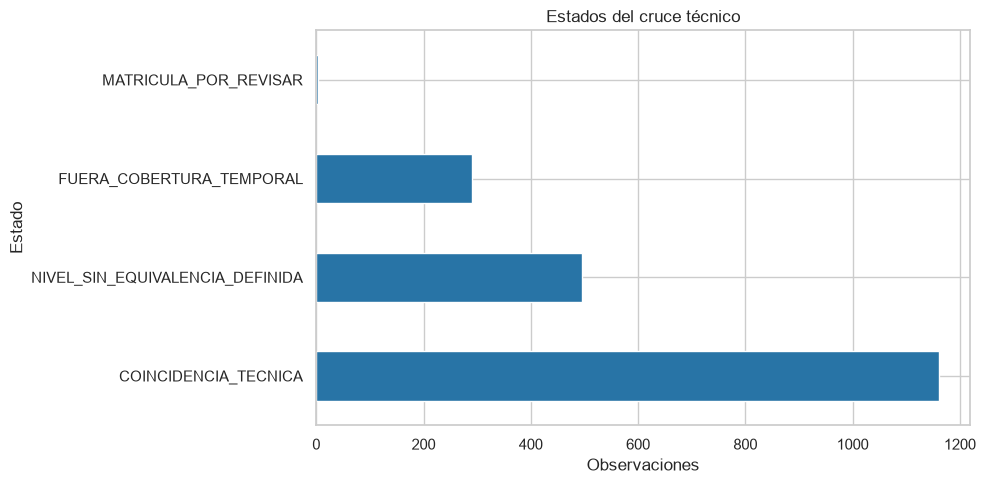

In [5]:
disponibilidad = df.groupby("nivel_formacion").agg(observaciones=("anio","size"), tasas_disponibles=("tasa_desercion","count"), coincidencias=("coincidio_matricula","sum"), pares_tecnicos=("par_sin_alertas_tecnicas","sum"))
disponibilidad["sin_tasa"] = disponibilidad["observaciones"]-disponibilidad["tasas_disponibles"]
disponibilidad["disponibilidad_pct"] = disponibilidad["tasas_disponibles"]/disponibilidad["observaciones"]*100
display(disponibilidad.round(2))
display(pd.crosstab(df["nivel_formacion"],df["estado_dato"],margins=True))
display(pd.crosstab(df["nivel_formacion"],df["estado_integracion_matricula"],margins=True))
with pd.option_context("display.max_rows",100):
    display(df.loc[~con_tasa,["departamento","nivel_formacion","anio","estado_dato","linea_origen"]].sort_values(["nivel_formacion","departamento","anio"]))
print("Matrícula pendiente de revisión numérica en el cruce:")
display(df.loc[df["requiere_revision_matricula"].fillna(False),["departamento","nivel_formacion","anio","matricula_reportada","estado_matricula"]])
fig,ax = plt.subplots(figsize=(10,5))
df["estado_integracion_matricula"].value_counts().plot.barh(ax=ax,color="#2874A6")
ax.set(title="Estados del cruce técnico",xlabel="Observaciones",ylabel="Estado")
fig.tight_layout()
plt.show()


## Indicadores de entrega
Se separan los indicadores descriptivos de deserción de las métricas técnicas de calidad. `cambio_anual_medio_pp` promedia los cambios de departamentos con comparación disponible; no necesariamente equivale a restar medias anuales con coberturas distintas.


In [6]:
ruta_ind = RAIZ / "data/gold/gold_indicadores_por_nivel_anio.csv"
ruta_calidad = RAIZ / "data/gold/gold_resumen_calidad.csv"
for ruta in [ruta_ind,ruta_calidad]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {ruta.name}. Ejecuta main.py.")
indicadores = pd.read_csv(ruta_ind,encoding="utf-8-sig")
resumen_calidad = pd.read_csv(ruta_calidad,encoding="utf-8-sig")
if indicadores.duplicated(["nivel_formacion","anio"]).any():
    raise ValueError("Indicadores con claves repetidas.")
display(resumen_calidad)
with pd.option_context("display.max_rows",100):
    display(indicadores.round(3))


,metrica,valor,unidad
0,observaciones_gold,1950.000000,observaciones
1,tasas_disponibles,1901.000000,observaciones
2,observaciones_no_aplica,49.000000,observaciones
3,observaciones_sin_dato,0.000000,observaciones
4,disponibilidad_tasa_pct,97.487179,porcentaje_de_filas_gold
5,cobertura_cruce_pct,59.692308,porcentaje_de_filas_gold
6,pares_sin_alertas_tecnicas,1131.000000,observaciones
7,variaciones_anuales_calculadas,1762.000000,comparaciones


,nivel_formacion,anio,departamentos_presentes,departamentos_con_tasa,departamentos_no_aplica,departamentos_sin_dato,tasa_media_simple_pct,tasa_mediana_pct,tasa_minima_pct,tasa_maxima_pct,cambio_anual_medio_pp,departamentos_con_variacion,coincidencias_matricula,pares_sin_alertas_tecnicas,disponibilidad_tasa_pct,cobertura_cruce_pct,tipo_agregacion
0,Tecnológico,2010,33,30,3,0,27.081,21.003,7.535,62.500,NaN,0,33,30,90.909,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
1,Tecnológico,2011,33,32,1,0,23.344,15.832,3.371,81.818,-3.960,30,33,32,96.970,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
2,Tecnológico,2012,33,33,0,0,7.856,8.006,0.000,19.131,-15.242,32,33,32,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
3,Tecnológico,2013,33,33,0,0,7.410,7.681,0.000,17.607,-0.446,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
4,Tecnológico,2014,33,33,0,0,13.983,13.594,2.564,32.983,6.573,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
5,Tecnológico,2015,33,33,0,0,14.732,12.373,3.926,40.588,0.749,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
6,Tecnológico,2016,33,33,0,0,13.101,13.274,4.469,19.540,-1.631,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
7,Tecnológico,2017,33,33,0,0,11.379,9.708,2.652,45.322,-1.722,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
8,Tecnológico,2018,33,33,0,0,10.447,9.820,4.159,20.280,-0.932,33,33,33,100.000,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA
9,Tecnológico,2019,33,31,2,0,15.964,13.575,0.000,50.000,6.056,31,33,31,93.939,100.0,DESCRIPTIVA_DEPARTAMENTAL_NO_PONDERADA


## Estadísticas y evolución
Las estadísticas reúnen tasas departamentales disponibles; no se ponderan con matrícula.


,count,mean,std,min,25%,50%,75%,max
nivel_formacion,,,,,,,,
Tecnológico,482.0,14.34,9.81,0.0,9.4,12.58,16.48,81.82
TyT,488.0,15.21,10.16,0.0,10.12,13.17,17.15,81.82
Técnico Profesional,436.0,19.59,15.42,0.0,11.13,16.49,23.08,100.0
Universitario,495.0,10.6,6.04,0.0,7.48,9.16,11.43,60.42


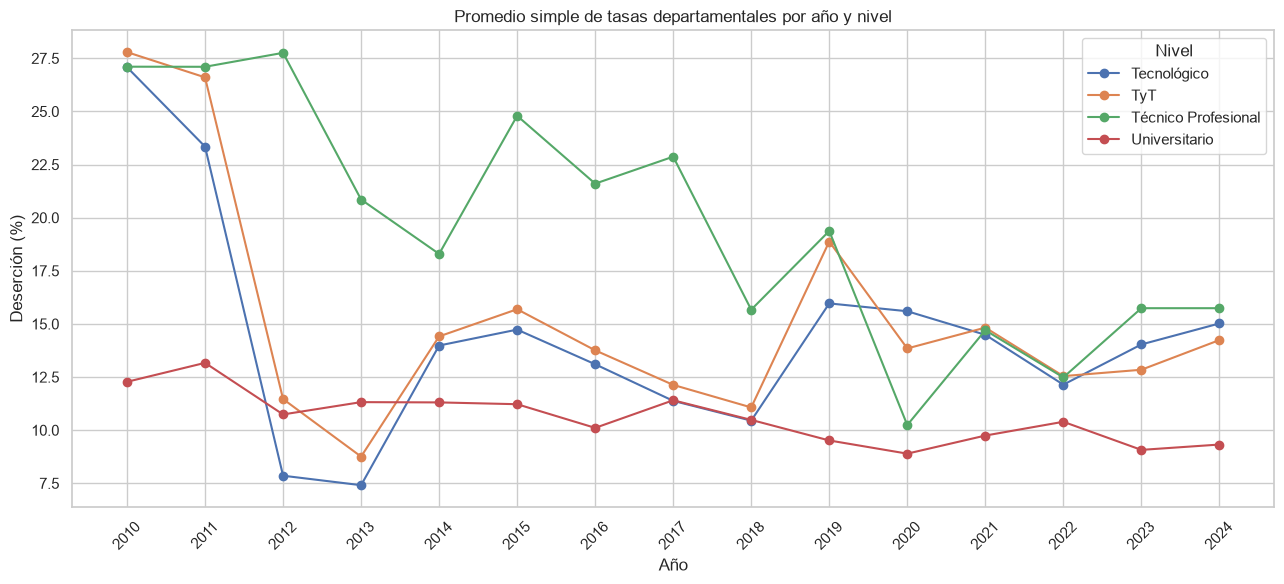

nivel_formacion,Tecnológico,TyT,Técnico Profesional,Universitario
anio,,,,
2010,30,31,26,33
2011,32,33,28,33
2012,33,33,28,33
2013,33,33,29,33
2014,33,33,30,33
2015,33,33,31,33
2016,33,33,31,33
2017,33,33,31,33
2018,33,33,29,33


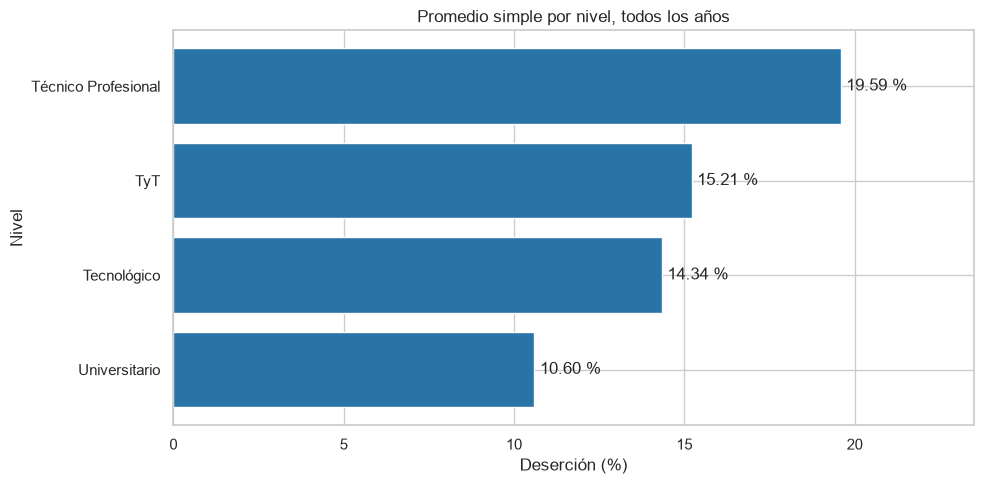

,nivel_formacion,promedio_pct,tasas_disponibles
2,Técnico Profesional,19.59,436
1,TyT,15.21,488
0,Tecnológico,14.34,482
3,Universitario,10.6,495


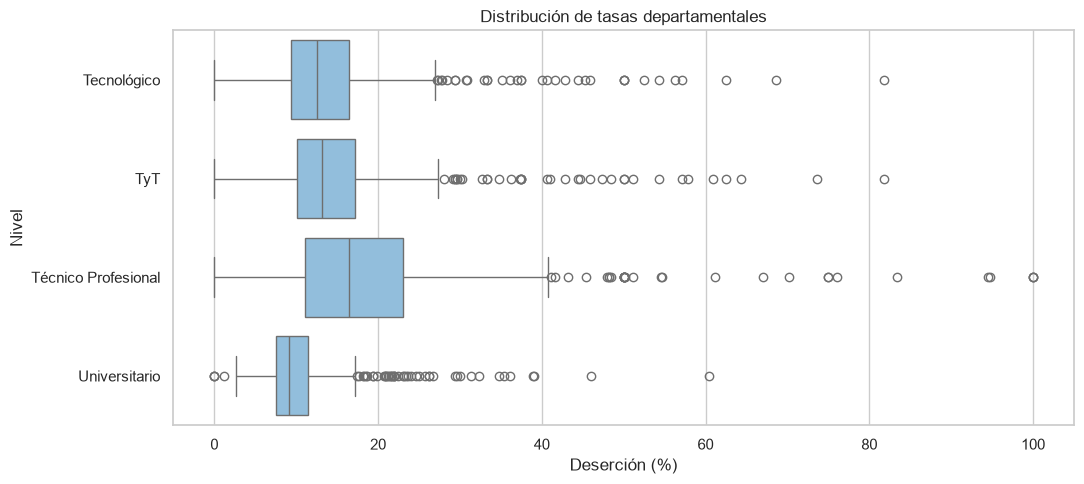

In [7]:
display(df.groupby("nivel_formacion")["tasa_desercion_porcentaje"].describe().round(2))
evolucion = df.groupby(["anio","nivel_formacion"],as_index=False).agg(promedio_pct=("tasa_desercion_porcentaje","mean"),departamentos_con_tasa=("tasa_desercion","count"))
fig,ax = plt.subplots(figsize=(13,6))
for nivel,grupo in evolucion.groupby("nivel_formacion"):
    grupo = grupo.sort_values("anio")
    ax.plot(grupo["anio"],grupo["promedio_pct"],marker="o",label=nivel)
ax.set(title="Promedio simple de tasas departamentales por año y nivel",xlabel="Año",ylabel="Deserción (%)")
ax.set_xticks(sorted(df["anio"].unique()))
ax.tick_params(axis="x",rotation=45)
ax.legend(title="Nivel")
fig.tight_layout()
plt.show()
display(evolucion.pivot(index="anio",columns="nivel_formacion",values="departamentos_con_tasa"))
resumen_nivel = df.groupby("nivel_formacion",as_index=False).agg(promedio_pct=("tasa_desercion_porcentaje","mean"),tasas_disponibles=("tasa_desercion","count")).sort_values("promedio_pct",ascending=False)
fig,ax = plt.subplots(figsize=(10,5))
barras = ax.barh(resumen_nivel["nivel_formacion"],resumen_nivel["promedio_pct"],color="#2874A6")
ax.invert_yaxis()
ax.bar_label(barras,labels=[f"{v:.2f} %" for v in resumen_nivel["promedio_pct"]],padding=4)
ax.set_xlim(0,resumen_nivel["promedio_pct"].max()*1.2)
ax.set(title="Promedio simple por nivel, todos los años",xlabel="Deserción (%)",ylabel="Nivel")
fig.tight_layout()
plt.show()
display(resumen_nivel.round(2))
fig,ax = plt.subplots(figsize=(11,5))
sns.boxplot(data=df,x="tasa_desercion_porcentaje",y="nivel_formacion",color="#85C1E9",ax=ax)
ax.set(title="Distribución de tasas departamentales",xlabel="Deserción (%)",ylabel="Nivel")
fig.tight_layout()
plt.show()


## Variaciones anuales
Pasar de 10 % a 12 % es aumentar 2 puntos porcentuales, no 2 % relativo. Solo se comparan años consecutivos con tasas disponibles.


Variaciones calculables: 1,762
Mayores aumentos:


,departamento,nivel_formacion,anio,tasa_anterior_comparable,tasa_desercion,variacion_desercion_pp
1357,Arauca,Técnico Profesional,2017,0.0,1.0,100.0
1164,Chocó,Técnico Profesional,2019,0.1,0.947917,84.791667
1161,Chocó,Técnico Profesional,2016,0.026667,0.833333,80.666667
1355,Arauca,Técnico Profesional,2015,0.285714,1.0,71.428571
1434,Guainía,Técnico Profesional,2019,0.1,0.75,65.0
669,Chocó,TyT,2019,0.108401,0.609467,50.106637
445,Guainía,Tecnológico,2020,0.0,0.5,50.0
1093,Caquetá,Técnico Profesional,2023,0.0,0.5,50.0
489,Vichada,Tecnológico,2019,0.041594,0.5,45.840555
984,Vichada,TyT,2019,0.041594,0.5,45.840555


Mayores disminuciones:


,departamento,nivel_formacion,anio,tasa_anterior_comparable,tasa_desercion,variacion_desercion_pp
1356,Arauca,Técnico Profesional,2016,1.0,0.0,-100.0
1165,Chocó,Técnico Profesional,2020,0.947917,0.037736,-91.018082
467,Vaupés,Tecnológico,2012,0.818182,0.0,-81.818182
962,Vaupés,TyT,2012,0.818182,0.0,-81.818182
1162,Chocó,Técnico Profesional,2017,0.833333,0.059701,-77.363184
1435,Guainía,Técnico Profesional,2020,0.75,0.0,-75.0
482,Vichada,Tecnológico,2012,0.685714,0.0,-68.571429
1308,Sucre,Técnico Profesional,2013,0.670626,0.042914,-62.771218
917,Amazonas,TyT,2012,0.642857,0.032864,-60.999329
977,Vichada,TyT,2012,0.578313,0.0,-57.831325


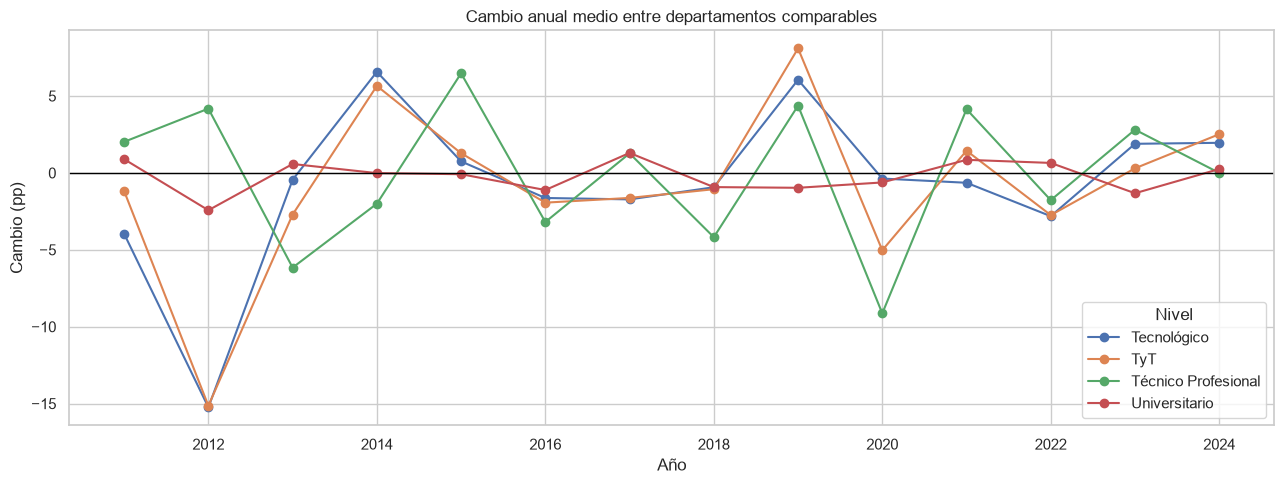

In [8]:
variaciones = df.loc[df["variacion_calculable"].fillna(False)].copy()
cols = ["departamento","nivel_formacion","anio","tasa_anterior_comparable","tasa_desercion","variacion_desercion_pp"]
print(f"Variaciones calculables: {len(variaciones):,}")
print("Mayores aumentos:")
display(variaciones.nlargest(10,"variacion_desercion_pp")[cols])
print("Mayores disminuciones:")
display(variaciones.nsmallest(10,"variacion_desercion_pp")[cols])
resumen_cambio = variaciones.groupby(["anio","nivel_formacion"],as_index=False).agg(cambio_medio_pp=("variacion_desercion_pp","mean"),pares_departamentales=("variacion_desercion_pp","count"))
fig,ax = plt.subplots(figsize=(13,5))
for nivel,grupo in resumen_cambio.groupby("nivel_formacion"):
    ax.plot(grupo["anio"],grupo["cambio_medio_pp"],marker="o",label=nivel)
ax.axhline(0,color="black",linewidth=1)
ax.set(title="Cambio anual medio entre departamentos comparables",xlabel="Año",ylabel="Cambio (pp)")
ax.legend(title="Nivel")
fig.tight_layout()
plt.show()


## Rankings del 20 %
El ranking departamental de gold selecciona ceil(20 % de departamentos con tasa) por año y nivel; los empates se resuelven por código. Las selecciones no son departamentos únicos ni pruebas de significancia.

Como complemento para el KR2 original, se selecciona también el 20 % de años con mayores promedios por nivel; se redondea hacia arriba y los empates se resuelven por año. Esta operacionalización es descriptiva y requiere validación académica; no reemplaza un ranking institucional.


,departamento,tasa_desercion_porcentaje,posicion_tasa,cantidad_top20_grupo
1949,Vichada,19.858156,1,7
1934,Vaupés,19.379845,2,7
1904,Guainía,18.133333,3,7
1889,Amazonas,14.596273,4,7
1919,Guaviare,12.274368,5,7
1859,Putumayo,11.818182,6,7
1844,Casanare,10.8573,7,7


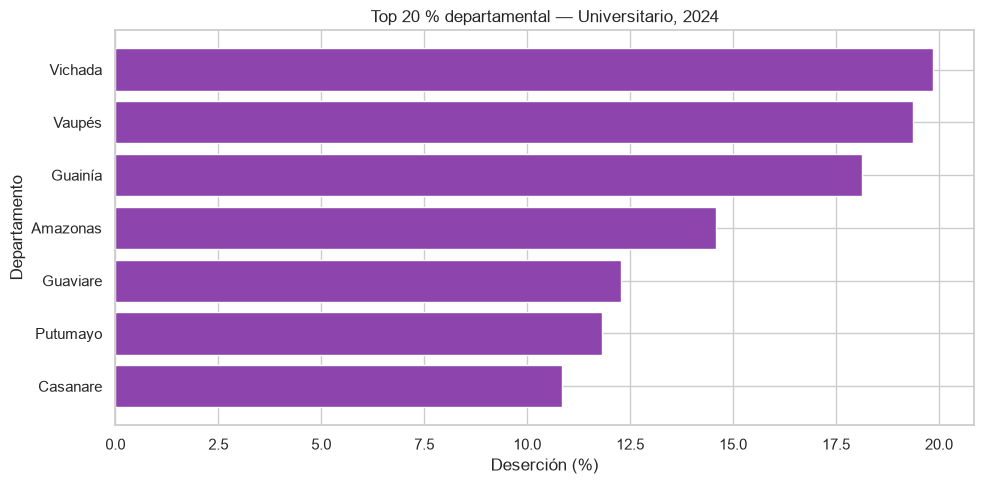

Periodos del 20 % superior por nivel:


,anio,nivel_formacion,promedio_pct,departamentos_con_tasa,posicion,cantidad_seleccionada
0,2010,Tecnológico,27.081039,30,1,3
4,2011,Tecnológico,23.343929,32,2,3
36,2019,Tecnológico,15.964325,31,3,3
1,2010,TyT,27.790471,31,1,3
5,2011,TyT,26.60252,33,2,3
37,2019,TyT,18.876162,32,3,3
10,2012,Técnico Profesional,27.756964,28,1,3
2,2010,Técnico Profesional,27.104832,26,2,3
6,2011,Técnico Profesional,27.10018,28,3,3
7,2011,Universitario,13.166577,33,1,3


In [9]:
ANIO_SELECCIONADO = int(df["anio"].max())
NIVEL_SELECCIONADO = "Universitario"
seleccion = df.loc[df["anio"].eq(ANIO_SELECCIONADO) & df["nivel_formacion"].eq(NIVEL_SELECCIONADO) & df["es_top20_departamental"].fillna(False)].sort_values("posicion_tasa")
display(seleccion[["departamento","tasa_desercion_porcentaje","posicion_tasa","cantidad_top20_grupo"]])
if not seleccion.empty:
    fig,ax = plt.subplots(figsize=(10,5))
    ax.barh(seleccion["departamento"],seleccion["tasa_desercion_porcentaje"],color="#8E44AD")
    ax.invert_yaxis()
    ax.set(title=f"Top 20 % departamental — {NIVEL_SELECCIONADO}, {ANIO_SELECCIONADO}",xlabel="Deserción (%)",ylabel="Departamento")
    fig.tight_layout()
    plt.show()
ranking_periodos = evolucion.dropna(subset=["promedio_pct"]).sort_values(["nivel_formacion","promedio_pct","anio"],ascending=[True,False,True]).copy()
gp = ranking_periodos.groupby("nivel_formacion")
ranking_periodos["posicion"] = gp.cumcount()+1
ranking_periodos["cantidad_seleccionada"] = np.ceil(gp["anio"].transform("size")*0.20).astype(int)
print("Periodos del 20 % superior por nivel:")
display(ranking_periodos.loc[ranking_periodos["posicion"] <= ranking_periodos["cantidad_seleccionada"]])


## Exploración conjunta de matrícula y deserción
Se muestran pares universitarios sin alertas técnicas definidas. Esto no certifica comparabilidad metodológica. Se limita a un nivel para no mezclar categorías ni asumir un tratamiento común del SENA en tecnológica.

Cada punto es departamento × año; las observaciones repetidas de un territorio no son independientes. No se interpreta el gráfico como causal ni se ajusta una regresión. La matrícula no se utiliza como denominador.


Pares técnicos de todos los niveles: 1,131; universitarios mostrados: 394


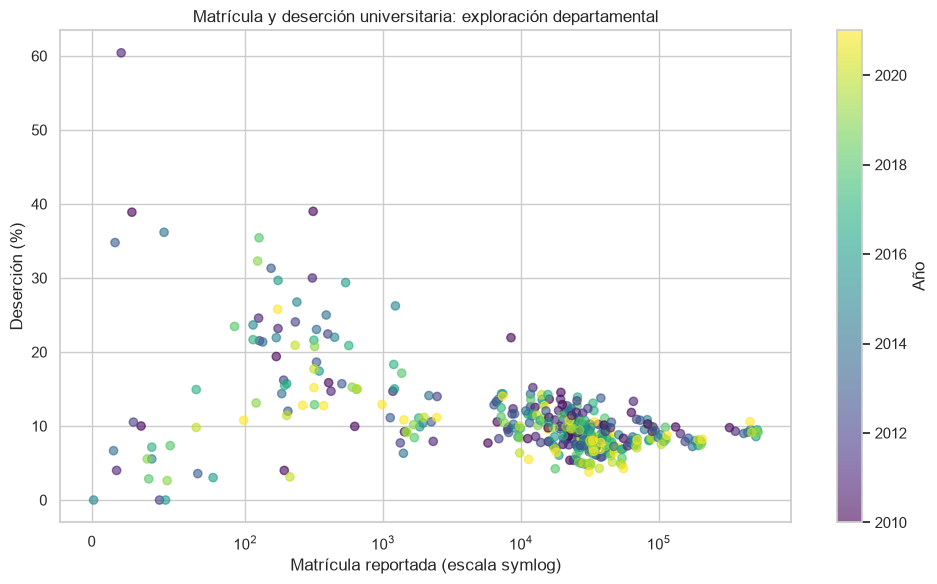

In [10]:
pares = df.loc[df["par_sin_alertas_tecnicas"].fillna(False)]
pares_u = pares.loc[pares["nivel_formacion"].eq("Universitario")]
print(f"Pares técnicos de todos los niveles: {len(pares):,}; universitarios mostrados: {len(pares_u):,}")
if not pares_u.empty:
    fig,ax = plt.subplots(figsize=(10,6))
    puntos = ax.scatter(pares_u["matricula_reportada"].astype(float),pares_u["tasa_desercion_porcentaje"].astype(float),c=pares_u["anio"].astype(float),cmap="viridis",alpha=0.6)
    ax.set_xscale("symlog",linthresh=100)
    ax.set(title="Matrícula y deserción universitaria: exploración departamental",xlabel="Matrícula reportada (escala symlog)",ylabel="Deserción (%)")
    fig.colorbar(puntos,ax=ax,label="Año")
    fig.tight_layout()
    plt.show()


## Hallazgos descriptivos
Estos resultados no equivalen a cinco factores causales ni demuestran por sí solos cinco tendencias del planteamiento.


In [11]:
mayor = resumen_nivel.iloc[0]
menor = resumen_nivel.iloc[-1]
nivel_faltantes = disponibilidad["sin_tasa"].idxmax()
hallazgos = [f'Mayor promedio simple: {mayor["nivel_formacion"]}, {mayor["promedio_pct"]:.2f} %.',f'Menor promedio simple: {menor["nivel_formacion"]}, {menor["promedio_pct"]:.2f} %.',f'Más observaciones sin tasa: {nivel_faltantes}, {int(disponibilidad.loc[nivel_faltantes,"sin_tasa"])}.']
if not variaciones.empty:
    for titulo,indice in [("Cambio máximo",variaciones["variacion_desercion_pp"].idxmax()),("Cambio mínimo",variaciones["variacion_desercion_pp"].idxmin())]:
        fila = variaciones.loc[indice]
        hallazgos.append(f'{titulo}: {fila["variacion_desercion_pp"]:.2f} pp, {fila["departamento"]}, {fila["nivel_formacion"]}, {int(fila["anio"])}. Puede haber empates.')
display(pd.DataFrame({"hallazgo":hallazgos}))


,hallazgo
0,"Mayor promedio simple: Técnico Profesional, 19..."
1,"Menor promedio simple: Universitario, 10.60 %."
2,Más observaciones sin tasa: Técnico Profesiona...
3,"Cambio máximo: 100.00 pp, Arauca, Técnico Prof..."
4,"Cambio mínimo: -100.00 pp, Arauca, Técnico Pro..."


## Evaluación de las preguntas originales
No se sustituyen instituciones por departamentos ni permanencia por deserción para aumentar la cobertura. Una respuesta parcial no cuenta como completa. Esta evaluación es explícita y conservadora, no una calificación docente.


In [12]:
preguntas = [
(1,"Evolución de deserción en Colombia","Parcial","Promedios departamentales por nivel, no tasa nacional ponderada."),
(2,"Instituciones con mayores y menores tasas","Sin datos","Faltan registros institucionales."),
(3,"Comparación de niveles de formación","Respondida","Comparación descriptiva de tasas disponibles."),
(4,"Deserción y permanencia entre instituciones","Sin datos","Faltan instituciones y permanencia."),
(5,"Relación de matrícula con deserción y permanencia","Parcial","Cruce exploratorio; falta permanencia y comparabilidad confirmada."),
(6,"Periodos con mayores variaciones de deserción y permanencia","Parcial","Variaciones de deserción, no de permanencia."),
(7,"Instituciones o niveles con cambios significativos","Parcial","Cambios descriptivos; sin prueba de significancia ni instituciones."),
(8,"Instituciones, niveles o periodos de mayor riesgo","Parcial","Rankings descriptivos, no riesgo validado."),
(9,"Patrones entre instituciones y niveles","Parcial","Comparaciones por nivel, no por institución."),
(10,"Información útil para seguimiento y estrategias","Respondida","Calidad, cobertura, tasas y cambios; sin evaluación de impacto.")]
cobertura_preguntas = pd.DataFrame(preguntas,columns=["numero","pregunta","estado","evidencia_o_limite"])
with pd.option_context("display.max_colwidth",120):
    display(cobertura_preguntas)
respondidas = int(cobertura_preguntas["estado"].eq("Respondida").sum())
print(f"Cobertura estricta bajo esta evaluación: {respondidas}/10 = {respondidas/10*100:.0f} %.")
print("La meta del 90 % no se declara cumplida. Las respuestas parciales no se cuentan como completas.")


,numero,pregunta,estado,evidencia_o_limite
0,1,Evolución de deserción en Colombia,Parcial,"Promedios departamentales por nivel, no tasa nacional ponderada."
1,2,Instituciones con mayores y menores tasas,Sin datos,Faltan registros institucionales.
2,3,Comparación de niveles de formación,Respondida,Comparación descriptiva de tasas disponibles.
3,4,Deserción y permanencia entre instituciones,Sin datos,Faltan instituciones y permanencia.
4,5,Relación de matrícula con deserción y permanencia,Parcial,Cruce exploratorio; falta permanencia y comparabilidad confirmada.
5,6,Periodos con mayores variaciones de deserción y permanencia,Parcial,"Variaciones de deserción, no de permanencia."
6,7,Instituciones o niveles con cambios significativos,Parcial,Cambios descriptivos; sin prueba de significancia ni instituciones.
7,8,"Instituciones, niveles o periodos de mayor riesgo",Parcial,"Rankings descriptivos, no riesgo validado."
8,9,Patrones entre instituciones y niveles,Parcial,"Comparaciones por nivel, no por institución."
9,10,Información útil para seguimiento y estrategias,Respondida,"Calidad, cobertura, tasas y cambios; sin evaluación de impacto."


Cobertura estricta bajo esta evaluación: 2/10 = 20 %.
La meta del 90 % no se declara cumplida. Las respuestas parciales no se cuentan como completas.


## Estado de los objetivos e indicadores originales
| Elemento | Estado |
|---|---|
| KR1: cinco factores o características asociados | Parcial: año, territorio y nivel; no cinco factores independientes ni causas. |
| KR2: 20 % de instituciones, niveles o periodos | Selección descriptiva de periodos implementada; requiere aprobación de la operacionalización. Ranking departamental complementario. |
| KR3: cinco patrones de deserción y permanencia | Parcial: hallazgos descriptivos de deserción, no permanencia ni tendencias validadas. |
| KR4: evolución de todos los periodos | Todos los años disponibles de deserción se muestran; falta permanencia y matrícula 2022–2024. |
| KR5: responder al menos 90 % de preguntas | No alcanzado en esta evaluación estricta. |
| Tasa de deserción | Disponible a nivel departamental, por nivel y año. |
| Cantidad de desertores | No calculable justificadamente con estos insumos. |
| Permanencia | No disponible; no se obtiene automáticamente como 100 menos deserción. |
| Variación | Disponible entre años consecutivos en puntos porcentuales. |
| Tasa institucional | No disponible. |

El cumplimiento técnico de la directriz Excel + API, transformación, JOIN, gold e indicadores no equivale al cumplimiento de todos los objetivos amplios del Avance 1. Estos últimos requieren fuentes adicionales compatibles o una reformulación aprobada.


In [13]:
total = len(df)
reportadas = int(con_tasa.sum())
no_aplica = int(df["estado_dato"].eq("no_aplica").sum())
sin_dato = int(df["estado_dato"].eq("sin_dato").sum())
cruzadas = int(df["coincidio_matricula"].fillna(False).sum())
pares_total = int(df["par_sin_alertas_tecnicas"].fillna(False).sum())
texto = f"""
## Conclusiones y límites
1. Gold conserva {total:,} observaciones y {reportadas:,} tasas disponibles. Se identifican {no_aplica} no aplicables y {sin_dato} sin dato; no se sustituyeron por cero.
2. Hay {cruzadas:,} coincidencias técnicas de matrícula ({cruzadas/total*100:.2f} % de las filas) y {pares_total:,} pares con tasa y matrícula sin las alertas técnicas definidas. No certifica comparabilidad metodológica.
3. Se calcularon {len(variaciones):,} variaciones anuales sin saltar años faltantes. El ranking departamental no equivale a un ranking institucional.
4. Se generaron {len(indicadores)} filas de indicadores por nivel y año. Los promedios son descriptivos, no tasas nacionales ponderadas.
5. La matrícula observada termina en 2021. TyT no tiene equivalencia de matrícula definida; las cifras decimales se conservan para revisión.
6. El análisis no demuestra causas, riesgo individual ni cantidades de desertores. Los objetivos institucionales, de permanencia y de cobertura del 90 % permanecen pendientes.
7. Las validaciones anteriores corresponden a controles definidos, no a una garantía absoluta de calidad. No se realizó carga a una base de datos.
"""
display(Markdown(texto))



## Conclusiones y límites
1. Gold conserva 1,950 observaciones y 1,901 tasas disponibles. Se identifican 49 no aplicables y 0 sin dato; no se sustituyeron por cero.
2. Hay 1,164 coincidencias técnicas de matrícula (59.69 % de las filas) y 1,131 pares con tasa y matrícula sin las alertas técnicas definidas. No certifica comparabilidad metodológica.
3. Se calcularon 1,762 variaciones anuales sin saltar años faltantes. El ranking departamental no equivale a un ranking institucional.
4. Se generaron 60 filas de indicadores por nivel y año. Los promedios son descriptivos, no tasas nacionales ponderadas.
5. La matrícula observada termina en 2021. TyT no tiene equivalencia de matrícula definida; las cifras decimales se conservan para revisión.
6. El análisis no demuestra causas, riesgo individual ni cantidades de desertores. Los objetivos institucionales, de permanencia y de cobertura del 90 % permanecen pendientes.
7. Las validaciones anteriores corresponden a controles definidos, no a una garantía absoluta de calidad. No se realizó carga a una base de datos.
